## 06 — Gaze Probability Analysis and Time-Course Visualization

In [ ]:
###Calculate gaze probabilities and log ratios, then plot the time course

In [80]:
import pandas as pd
from pathlib import Path


In [82]:
#Get the main project folder (moves up from 'notebooks' to root) ->Python_eye_tracking_2x2
project_folder = Path.cwd().parent

In [84]:
# Define project path and file location
csv_file_path = project_folder / "data" / "interim" / "et_data_aggregated_05.csv"

In [86]:
# Load the dataset back into pandas
et_data_aggregated_05 = pd.read_csv(csv_file_path)

In [87]:
et_data_aggregated_05.head()

,ParticipantName,items,Lists,RecordingTimestamp,time_diff,GazeEventDur_ms,Validity left,Validity right,EyeMovementType,GazePointX,...,out,Condition,AOI1,AOI2,Subject,Object,ROI,ms_onset,ms_rel,bin20_rel
0,part05,Item12c,List2,147132,7233,83,Valid,Valid,Fixation,756.0,...,2,OVS,Subject,Object,0,0,out,7003,230,220
1,part05,Item12c,List2,147141,7242,83,Valid,Valid,Fixation,758.0,...,2,OVS,Subject,Object,0,0,out,7003,239,220
2,part05,Item12c,List2,147149,7250,83,Valid,Valid,Fixation,760.0,...,2,OVS,Subject,Object,0,0,out,7003,247,240
3,part05,Item12c,List2,147157,7258,83,Valid,Valid,Fixation,757.0,...,2,OVS,Subject,Object,0,0,out,7003,255,240
4,part05,Item12c,List2,147166,7267,83,Invalid,Valid,Fixation,762.0,...,2,OVS,Subject,Object,0,0,out,7003,264,260


In [90]:
et_filtered =et_data_aggregated_05.copy()

In [92]:
#Aggregate gaze probabilities using relative time bins (bin20_rel)
participant_bins_rel = (
    et_filtered
    .dropna(subset=["bin20_rel", "Condition"])
    .groupby(["ParticipantName", "bin20_rel", "Condition", "pronoun"], as_index=False)
    .agg(
        p_subject=("Subject", "mean"),
        p_object=("Object", "mean")
    )
)

In [94]:
#Inspect the top 20 rows
print("--- Aggregated Data Preview ---")
display(participant_bins_rel.head(20))

--- Aggregated Data Preview ---


,ParticipantName,bin20_rel,Condition,pronoun,p_subject,p_object
0,part05,0,OVS,er,0.000000,0.000000
1,part05,0,OVS,ihn,0.181818,0.181818
2,part05,0,SVO,er,0.272727,0.363636
3,part05,0,SVO,ihn,0.000000,0.000000
4,part05,20,OVS,er,0.000000,0.000000
5,part05,20,OVS,ihn,0.250000,0.166667
6,part05,20,SVO,er,0.142857,0.428571
7,part05,20,SVO,ihn,0.000000,0.000000
8,part05,40,OVS,er,0.000000,0.000000
9,part05,40,OVS,ihn,0.153846,0.230769


In [96]:
# Verify that the aggregated gaze proportions fall within [0, 1].
print("\n--- Summary Statistics ---")
display(participant_bins_rel[["p_subject", "p_object"]].describe())


--- Summary Statistics ---


,p_subject,p_object
count,18923.000000,18923.000000
mean,0.216200,0.205819
std,0.251193,0.240094
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.181818,0.181818
75%,0.369318,0.333333
max,1.000000,1.000000


In [98]:
#Check number of unique participants and bins captured
print(f"\nUnique Participants: {participant_bins_rel['ParticipantName'].nunique()}")
print(f"Unique Time Bins:    {participant_bins_rel['bin20_rel'].nunique()}")
print(f"Conditions Evaluated: {participant_bins_rel['Condition'].unique().tolist()}")
print(f"Pronouns Evaluated: {participant_bins_rel['pronoun'].unique().tolist()}")


Unique Participants: 16
Unique Time Bins:    367
Conditions Evaluated: ['OVS', 'SVO']
Pronouns Evaluated: ['er', 'ihn']


In [100]:
import numpy as np

EPSILON = 0.001

participant_log_ratios_rel = participant_bins_rel.copy()

participant_log_ratios_rel["p_subject"] = np.where(
    participant_log_ratios_rel["p_subject"] == 0, EPSILON, participant_log_ratios_rel["p_subject"]
)
participant_log_ratios_rel["p_object"] = np.where(
    participant_log_ratios_rel["p_object"] == 0, EPSILON, participant_log_ratios_rel["p_object"]
)

In [102]:
# Calculate the log ratio of Subject to Object gaze proportions.
participant_log_ratios_rel["log_ratio"] = np.log(
    participant_log_ratios_rel["p_subject"] / participant_log_ratios_rel["p_object"]
)

In [104]:
# Inspect top 10 rows
participant_log_ratios_rel.head(10)

,ParticipantName,bin20_rel,Condition,pronoun,p_subject,p_object,log_ratio
0,part05,0,OVS,er,0.001000,0.001000,0.000000
1,part05,0,OVS,ihn,0.181818,0.181818,0.000000
2,part05,0,SVO,er,0.272727,0.363636,-0.287682
3,part05,0,SVO,ihn,0.001000,0.001000,0.000000
4,part05,20,OVS,er,0.001000,0.001000,0.000000
5,part05,20,OVS,ihn,0.250000,0.166667,0.405465
6,part05,20,SVO,er,0.142857,0.428571,-1.098612
7,part05,20,SVO,ihn,0.001000,0.001000,0.000000
8,part05,40,OVS,er,0.001000,0.001000,0.000000
9,part05,40,OVS,ihn,0.153846,0.230769,-0.405465


In [106]:
import matplotlib.pyplot as plt
import seaborn as sns

In [108]:
# Set clean visualization theme
sns.set_theme(style="whitegrid")

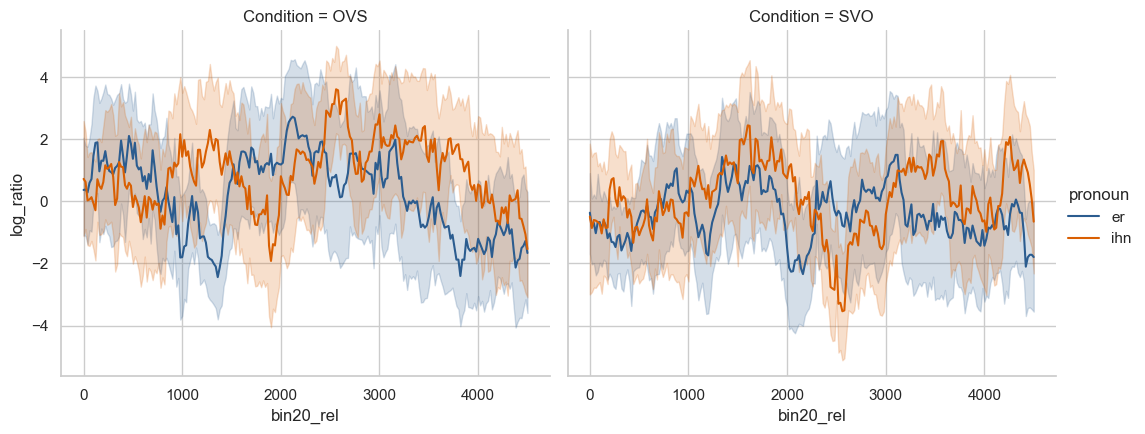

In [125]:
# Create faceted time-course line plot
g = sns.relplot(
    data=participant_log_ratios_rel[
        (participant_log_ratios_rel["bin20_rel"] >= 0) & 
        (participant_log_ratios_rel["bin20_rel"] <= 4500)
    ],
    x="bin20_rel",
    y="log_ratio",
    hue="pronoun",
    col="Condition",
    kind="line",
    height=4.5,
    aspect=1.2,
    palette={"er": "#2b5c8f", "ihn": "#d95f02"},
    errorbar=("ci", 95)  # Displays 95% confidence intervals across participants
)

plt.savefig("figure1_time_course.png", dpi=300, bbox_inches="tight")
# Update axis labels (x_label, y_label)
# g.set_axis_labels("bin20_rel (ms)", "time (ms)")

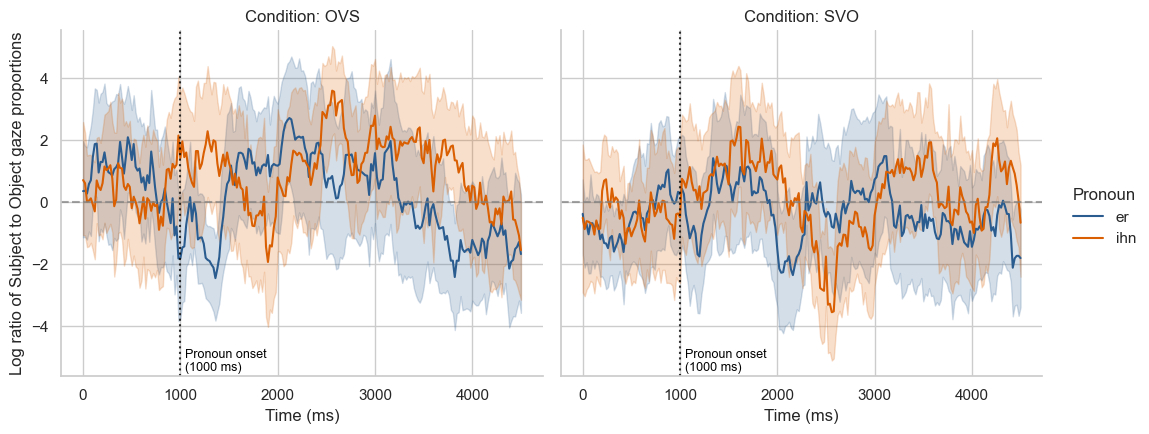

In [61]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Create a clean copy with the renamed column for the plot
plot_data = participant_log_ratios_rel.copy()
plot_data = plot_data.rename(columns={"bin20_rel": "Time (ms)"})

# 2. Generate the plot using the new column name
g = sns.relplot(
    data=plot_data[
        (plot_data["Time (ms)"] >= 0) & 
        (plot_data["Time (ms)"] <= 4500)
    ],
    x="Time (ms)",
    y="log_ratio",
    hue="pronoun",
    col="Condition",
    kind="line",
    height=4.5,
    aspect=1.2,
    palette={"er": "#2b5c8f", "ihn": "#d95f02"},
    errorbar=("ci", 95)  # Displays 95% confidence intervals across participants
)

# 3. Set your axis labels and titles
g.set_axis_labels(
    "Time (ms)", 
    "Log ratio of gaze proportions (Subject / Object)"
)
g.set_titles(col_template="Condition: {col_name}")

if g._legend:
    g._legend.set_title("Pronoun")

# 4. Add reference lines (y=0 for indifference, x=1000 for pronoun onset)
g.refline(y=0, linestyle="--", color="gray", alpha=0.7)
g.refline(x=1000, linestyle=":", color="black", alpha=0.8)

# 5. Add text annotation to the 1000 ms marker across all facets
for ax in g.axes.flat:
    # Get the current Y-axis limits to place the text near the top
    ymin, ymax = ax.get_ylim()
    
    ax.text(
        x=1050,                  # Slightly to the right of the 1000ms line
        y=ymax * -0.85,           # Positioned near the botton of the plot area
        s="Pronoun onset\n(1000 ms)", 
        fontsize=9,
        color="black",
        ha="left",
        va="top"
    )

plt.show()

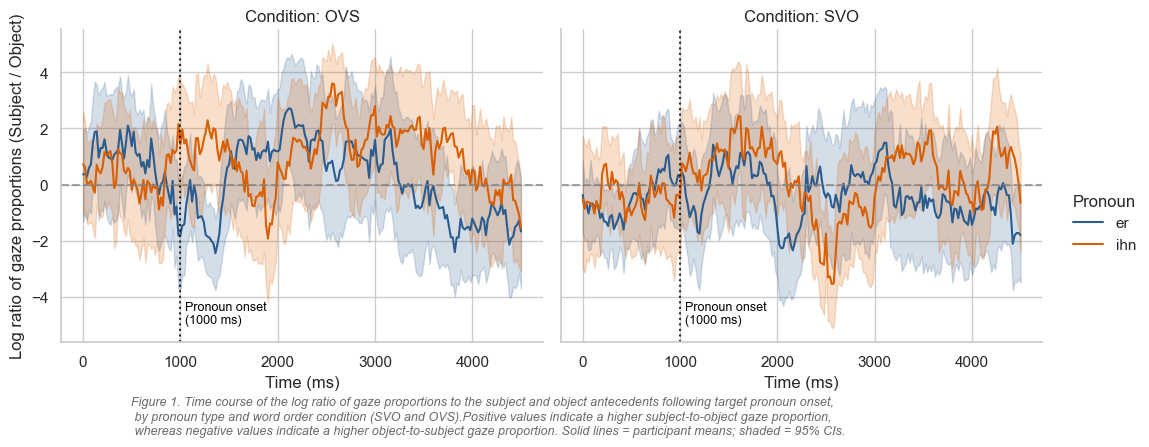

In [123]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Create a clean copy with the renamed column for the plot
plot_data = participant_log_ratios_rel.copy()
plot_data = plot_data.rename(columns={"bin20_rel": "Time (ms)"})

# 2. Generate the plot (increase bottom figure margin to make room for caption)
g = sns.relplot(
    data=plot_data[
        (plot_data["Time (ms)"] >= 0) & 
        (plot_data["Time (ms)"] <= 4500)
    ],
    x="Time (ms)",
    y="log_ratio",
    hue="pronoun",
    col="Condition",
    kind="line",
    height=4.5,
    aspect=1.2,
    palette={"er": "#2b5c8f", "ihn": "#d95f02"},
    errorbar=("ci", 95)
)

# 3. Axis labels and titles
g.set_axis_labels(
      "Time (ms)", 
    "Log ratio of gaze proportions (Subject / Object)"
)
g.set_titles(col_template="Condition: {col_name}")

if g._legend:
    g._legend.set_title("Pronoun")

# 4. Reference lines and text annotations
g.refline(y=0, linestyle="--", color="gray", alpha=0.7)
g.refline(x=1000, linestyle=":", color="black", alpha=0.8)

for ax in g.axes.flat:
    ymin, ymax = ax.get_ylim()
    ax.text(
        x=1050, 
        y=ymin + (ymax - ymin) * 0.05, 
        s="Pronoun onset\n(1000 ms)", 
        fontsize=9, color="black", ha="left", va="bottom"
    )

# 5. Add the figure caption at the very bottom of the canvas
caption_text = (
    "Figure 1. Time course of the log ratio of gaze proportions to the subject and object antecedents following target pronoun onset,\n by pronoun type and word order condition (SVO and OVS)." 
    "Positive values indicate a higher subject-to-object gaze proportion,\n whereas negative values indicate a higher object-to-subject gaze proportion. Solid lines = participant means; shaded = 95% CIs."
)

# Adjust layout to make space at the bottom for the text block
plt.subplots_adjust(bottom=0.22)

# Attach text to the figure canvas
plt.figtext(
    0.12, 0.02,                   # X and Y coordinates on the overall canvas
    caption_text, 
    wrap=True, 
    horizontalalignment='left', 
    fontsize=9, 
    style='italic',
    color='dimgray'
)

# Optional: Save the figure with the caption included
plt.savefig("figure2_time_course.png", dpi=300, bbox_inches="tight")

plt.show()

## Pipeline Summary and Quality Checks

This summary below reports dataset sizes at each processing stage and checks
whether stimulus and timing metadata could be matched to the eye-tracking data.

In [114]:
from pathlib import Path
import pandas as pd

project_folder = Path.cwd().parent
interim_folder = project_folder / "data" / "interim"
metadata_folder = project_folder / "data" / "metadata"

# Load the saved outputs from each processing stage
stage_files = {
    "Initial imported data": "raw_data_selected_01.csv",
    "Cleaned and binned data": "results_binned_02.csv",
    "After stimulus metadata merge": "et_data_joined_03.csv",
    "After AOI transformation": "et_data_transformed_04.csv",
    "After temporal alignment": "et_data_aggregated_05.csv",
}

stage_summary = []

for stage, filename in stage_files.items():
    df = pd.read_csv(interim_folder / filename)

    stage_summary.append({
        "Stage": stage,
        "Rows": len(df),
        "Participants": (
            df["ParticipantName"].nunique()
            if "ParticipantName" in df.columns
            else (
                df["Participant name"].nunique()
                if "Participant name" in df.columns
                else None
            )
        ),
    })

pipeline_summary = pd.DataFrame(stage_summary)

display(pipeline_summary)

,Stage,Rows,Participants
0,Initial imported data,504047,16
1,Cleaned and binned data,371510,16
2,After stimulus metadata merge,371510,16
3,After AOI transformation,371169,16
4,After temporal alignment,155326,16


In [116]:
# Load the eye-tracking data immediately before the stimulus merge
eye_tracking = pd.read_csv(
    interim_folder / "results_binned_02.csv"
)

# Load the stimulus metadata
stimuli = pd.read_csv(
    metadata_folder / "NomDat_experimental_stimuli.csv",
    sep=";"
).rename(columns={"Item": "items"})

# Compare unique stimulus IDs
eye_tracking_items = set(eye_tracking["items"].dropna().unique())
metadata_items = set(stimuli["items"].dropna().unique())

unmatched_items = eye_tracking_items - metadata_items

print(f"Unique eye-tracking stimulus IDs: {len(eye_tracking_items)}")
print(f"Unique metadata stimulus IDs:     {len(metadata_items)}")
print(f"Unmatched stimulus IDs:           {len(unmatched_items)}")
print(f"Unmatched IDs: {sorted(unmatched_items)}")

Unique eye-tracking stimulus IDs: 80
Unique metadata stimulus IDs:     80
Unmatched stimulus IDs:           0
Unmatched IDs: []


In [118]:
duplicate_metadata_ids = stimuli["items"].duplicated().sum()

print(f"Duplicate stimulus IDs in metadata: {duplicate_metadata_ids}")

Duplicate stimulus IDs in metadata: 0
